In [1]:
import os
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_spec = os.path.join('..', 'spec')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'pancan')
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'pancan')

In [3]:
# load agentic analysis results
fn = os.path.join(pth_spec, 'log.csv')
df = pd.read_csv(fn).set_index('JoinKey')

In [4]:
remove = ['Data_Ireland2020_Lung', 'Data_Jordan2016_Breast']
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata = adata[adata.obs.Name.isin(df.index)]
adata = adata[~adata.obs.Name.isin(remove)]
adata = sc.get.aggregate(adata, 'Name', 'mean')
adata.obs = adata.obs.join(df, 'Name'); adata

AnnData object with n_obs × n_vars = 86 × 245
    obs: 'Name', 'Title', 'Category', 'Disease', 'Run start', 'Run end', 'Expert interaction', 'Manifold geometry', 'Gate 1', 'Gate 2', 'Gate 3', 'Hub r', 'Attempts'
    layers: 'mean'

In [5]:
cols = ['Category', 'Disease']
var = ['Manifold geometry', 'Attempts']

# co-option rate (=prevalence) -> dot sizes
grp = adata.obs.groupby(cols, observed = True)
get_pos = lambda sdf: sdf[var[0]].notna()
get_prev = lambda sdf: get_pos(sdf).mean()
df_size = (grp.apply(get_prev, include_groups = False)
           .rename(var[0]).to_frame()
           .reset_index(level = cols[0], drop = True))
df_size.value_counts(sort = False)

Manifold geometry
0.000000              3
0.444444              1
0.500000              3
0.666667              3
0.750000              1
0.833333              1
1.000000             31
Name: count, dtype: int64

In [6]:
# detection rate (=TPR; 1st attempt) -> dot colors
get_tpr = lambda sdf: (sdf.loc[get_pos(sdf), var[1]] == 1
                       ).mean()
df_color = (grp.apply(get_tpr, include_groups = False)
            .rename(var[0]).to_frame()
            .reset_index(level = cols[0], drop = True))
df_color.value_counts(sort = False)

Manifold geometry
0.000000              8
0.333333              1
0.500000              2
0.600000              1
0.666667              2
0.750000              1
0.800000              2
1.000000             23
Name: count, dtype: int64

/home/caleb/miniconda3/envs/scanpy/lib/python3.13/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/caleb/tmp/ipykernel_4104684/1344513909.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cax.set_xticklabels([0, 50, 100])


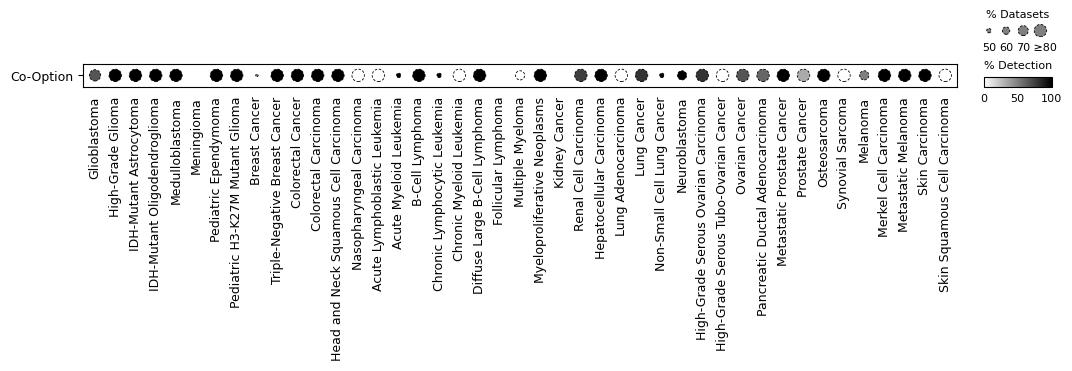

In [7]:
# prepare dummy adata for dotplot
df_plt = pd.concat((df_size, df_color), axis = 1)
obs = pd.DataFrame(df_plt.index)
adata_plt = ad.AnnData(X = df_plt.values, obs = obs)
adata_plt.var_names = pd.Index(var)

# results dotplot
fs1, fs2, dlim = 9, 8, [.4, .8]
dp = sc.pl.DotPlot(adata_plt, var[0], cols[1],
                   categories_order = df_plt.index,
                   dot_size_df = df_size,
                   dot_color_df = df_color,
                   vmin = 0, vmax = 1,
                   cmap = 'grey_r',
                   figsize = (12.5, .3)
                   ).style(
                    dot_min = dlim[0],
                    dot_max = dlim[1]
                   ).swap_axes()

dp.style(largest_dot = 80,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Datasets', size = fs2, pad = -5.5)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = 3.75)
ax_size.set_xticklabels(['50', '60', '70', '   ≥80'])
cax.set_title('% Detection', size = fs2, pad = 5.75)
cax.set_xticklabels([0, 50, 100])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 5)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_size.x0,
                      pos_main.y0 + 2.15 * pos_main.height,
                      pos_size.width,
                      5 * pos_size.height])

cax.set_position([pos_color.x0,
                  pos_main.y0 + .01 * pos_main.height,
                  pos_color.width,
                  6 * pos_color.height])

ax_main.set_yticklabels(['Co-Option'], fontsize = fs1)
ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        fontsize = fs1)
ax_main.tick_params('x', color = 'w')

lw, ls = .6, (0, (3, 2))
coll = ax_main.collections[0]
coll.set_linewidth(lw)
coll.set_linestyle(ls)
for coll in ax_size.collections:
    coll.set_linewidth(lw)
    coll.set_linestyle(ls)

fn = os.path.join(pth_out, 'cooption.pdf')
plt.savefig(fn, bbox_inches = 'tight')